# Pixel clustering of multiplexed images

Multiplexed imaging methods such as CODEX, MIBI, IMC or cyclic immunofluorescence measure tens of markers per pixel.
Clustering the pixels directly, without segmenting cells first, finds regions of similar marker expression: cell
types, but also extracellular structures. A common approach, used for example by
[spatiomic](https://spatiomic.org), is to fit a self-organising map on the pixels, cluster its nodes with Leiden
{cite:p}`Traag_2019` and give every pixel the cluster of its node. The map compresses the hundreds of thousands to
billions of pixels into a few hundred nodes, so the graph clustering stays small.

To keep this tutorial light and self-contained, it uses a synthetic image with known structures instead of a real one,
which also lets us check the result. On real data the steps are the same; see spatiomic's
[tutorial](https://spatiomic.org/latest/tutorials/full_example.html) for a full analysis of a real data set.

Besides fastersom, the tutorial uses [AnnData](https://anndata.readthedocs.io) and
[scanpy](https://scanpy.readthedocs.io) with [igraph](https://python.igraph.org) for Leiden clustering:

```bash
pip install fastersom scanpy igraph
```

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import ndimage
from sklearn.metrics import adjusted_rand_score

from fastersom import SOM

# the stored outputs were computed on the CPU, which is deterministic; None picks cuda > mps > cpu
DEVICE = "cpu"
plt.rcParams["figure.dpi"] = 80

## A synthetic multiplexed image

The image is 320 x 320 pixels with 11 channels. It shows tissue with glands of epithelium (some of it proliferating,
with Ki67), vessels with endothelium and smooth muscle, stroma, a lymphoid aggregate of B and T cells, and scattered
macrophages. Every structure has a profile of mean intensities over the channels; the image multiplies it by a smooth
random texture, blurs it slightly and adds shot noise. The code is hidden here; expand the cell to see it.

In [2]:
CHANNELS = ["DAPI", "panCK", "E-cadherin", "Ki67", "CD31", "aSMA", "Vimentin", "CD45", "CD3", "CD20", "CD68"]
# mean intensity of every channel (columns) in every structure (rows), in arbitrary units
PROFILES = pd.DataFrame(
    [
        [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
        [0.3, 0.0, 0.0, 0.0, 0.0, 0.1, 1.0, 0.0, 0.0, 0.0, 0.0],
        [0.8, 1.0, 0.8, 0.1, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
        [0.9, 1.0, 0.7, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
        [0.5, 0.0, 0.0, 0.0, 1.0, 0.0, 0.3, 0.0, 0.0, 0.0, 0.0],
        [0.4, 0.0, 0.0, 0.0, 0.0, 1.0, 0.4, 0.0, 0.0, 0.0, 0.0],
        [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 1.0, 1.0, 0.0, 0.0],
        [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 1.0, 0.0, 1.0, 0.0],
        [0.7, 0.0, 0.0, 0.0, 0.0, 0.0, 0.3, 0.6, 0.0, 0.0, 1.0],
    ],
    index=[
        "background",
        "stroma",
        "epithelium",
        "proliferating epithelium",
        "endothelium",
        "smooth muscle",
        "T cells",
        "B cells",
        "macrophages",
    ],
    columns=CHANNELS,
)


def synthetic_tissue(size: int = 320, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    """A (size, size, channels) image and the (size, size) index of the structure in PROFILES at every pixel."""
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[:size, :size]
    truth = np.ones((size, size), dtype=np.int64)  # stroma
    truth[xx > size * 0.85 + 12 * np.sin(yy / 23)] = 0  # no tissue beyond a wavy edge

    def disk(cy, cx, r):
        return (yy - cy) ** 2 + (xx - cx) ** 2 <= r**2

    for _ in range(14):  # glands: a ring of epithelium, some of it proliferating, around an empty lumen
        cy, cx, r = rng.uniform(30, size - 30), rng.uniform(30, size * 0.75), rng.uniform(16, 28)
        truth[disk(cy, cx, r) & ~disk(cy, cx, r - 8)] = 3 if rng.random() < 0.3 else 2
        truth[disk(cy, cx, r - 8)] = 0
    for _ in range(7):  # vessels: endothelium inside a wall of smooth muscle
        cy, cx, r = rng.uniform(15, size - 15), rng.uniform(15, size * 0.8), rng.uniform(8, 12)
        stroma = truth == 1
        truth[disk(cy, cx, r + 5) & stroma] = 5
        truth[disk(cy, cx, r) & stroma] = 4
        truth[disk(cy, cx, r - 3) & stroma] = 0
    # a lymphoid aggregate of B cells surrounded by T cells, and macrophages scattered over the stroma
    centre = (size * 0.7, size * 0.35)
    for label, n_cells, spread in ((7, 80, 12), (6, 160, 24), (8, 60, None)):
        for _ in range(n_cells):
            y, x = rng.uniform(0, size, 2) if spread is None else rng.normal(centre, spread)
            truth[disk(y, x, 4) & (truth == 1)] = label
    # intensities: the structure's profile times a smooth texture, blurred like an optical image, with shot noise
    texture = np.exp(1.5 * ndimage.gaussian_filter(rng.normal(size=(size, size, len(CHANNELS))), (4, 4, 0)))
    image = ndimage.gaussian_filter(PROFILES.to_numpy()[truth] * texture, (0.7, 0.7, 0)) + 0.02
    image = rng.poisson(image * 200) / 200
    return image.astype(np.float32), truth

In [3]:
image, truth = synthetic_tissue()
print(image.shape)
PROFILES

(320, 320, 11)


,DAPI,panCK,E-cadherin,Ki67,CD31,aSMA,Vimentin,CD45,CD3,CD20,CD68
background,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
stroma,0.3,0.0,0.0,0.0,0.0,0.1,1.0,0.0,0.0,0.0,0.0
epithelium,0.8,1.0,0.8,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
proliferating epithelium,0.9,1.0,0.7,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
endothelium,0.5,0.0,0.0,0.0,1.0,0.0,0.3,0.0,0.0,0.0,0.0
smooth muscle,0.4,0.0,0.0,0.0,0.0,1.0,0.4,0.0,0.0,0.0,0.0
T cells,1.0,0.0,0.0,0.0,0.0,0.0,0.1,1.0,1.0,0.0,0.0
B cells,1.0,0.0,0.0,0.0,0.0,0.0,0.1,1.0,0.0,1.0,0.0
macrophages,0.7,0.0,0.0,0.0,0.0,0.0,0.3,0.6,0.0,0.0,1.0


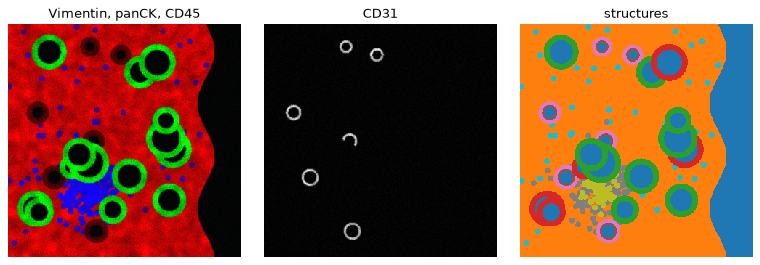

In [4]:
def show(images, titles, cmaps, size=3.2):
    _, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), layout="constrained")
    for ax, img, title, cmap in zip(axes, images, titles, cmaps, strict=True):
        ax.imshow(img, cmap=cmap, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")


rgb = image[..., [CHANNELS.index(c) for c in ("Vimentin", "panCK", "CD45")]]
rgb = np.clip(rgb / np.percentile(rgb, 99.5, axis=(0, 1)), 0, 1)
show(
    [rgb, image[..., CHANNELS.index("CD31")], truth],
    ["Vimentin, panCK, CD45", "CD31", "structures"],
    [None, "gray", "tab10"],
)

## Preprocessing

The SOM compares pixels by euclidean distance, so every channel should span a similar range. As in spatiomic's
tutorial, we clip each channel to percentiles and scale it to 0-1. fastersom takes the image as it is: an array of
shape `(height, width, channels)` is treated as `height x width` samples of `channels` features.

In [5]:
low, high = np.percentile(image, [1, 99.5], axis=(0, 1))
pixels = np.clip((image - low) / (high - low), 0, 1)

## Fitting the map

We fit a 20 x 20 map on all 102,400 pixels. Real images have far more pixels; fit the map on a random subsample of
them, for example a few hundred thousand, and then assign all pixels with `predict`, which processes them in batches
(see [](../guide/batch-size.md)).

In [6]:
som = SOM(n_rows=20, n_cols=20, n_epochs=10, random_state=0, device=DEVICE)
%time som.fit(pixels)
print(f"quantization error {som.quantization_error(pixels):.4f}")
print(f"topographic error {som.topographic_error(pixels):.4f}")

CPU times: user 600 ms, sys: 29.9 ms, total: 630 ms
Wall time: 232 ms
quantization error 0.0506
topographic error 0.0579


## Leiden clustering of the nodes

The 400 nodes go into an AnnData object, one observation per node, so that scanpy builds their k-nearest-neighbour
graph and finds Leiden communities, as it would for cells.

In [7]:
nodes = ad.AnnData(som.weights_, var=pd.DataFrame(index=CHANNELS))
sc.pp.neighbors(nodes, n_neighbors=15, use_rep="X", random_state=0)
sc.tl.leiden(nodes, resolution=1.0, flavor="igraph", n_iterations=2, directed=False, random_state=0)
nodes.obs["leiden"].value_counts().sort_index().to_frame("nodes").T

leiden,0,1,2,3,4,5,6,7,8,9,10,11,12
nodes,46,11,54,21,23,25,41,13,34,35,39,44,14


Every pixel gets the cluster of its node, and the clusters, reshaped to the image, give a cluster map. Here the
pixels also go into an AnnData object, with their cluster and coordinates, for scanpy's plots.

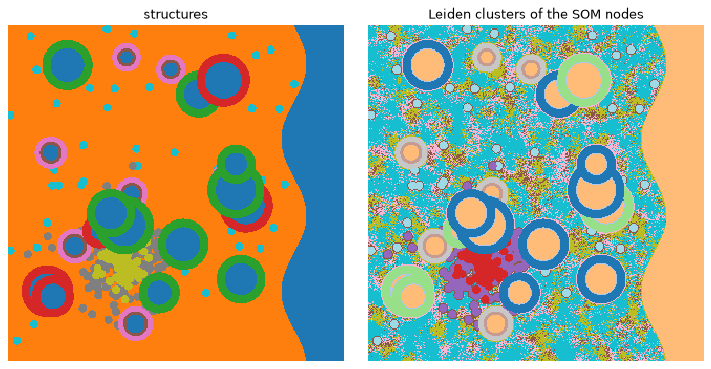

In [8]:
node_cluster = nodes.obs["leiden"].to_numpy()
pixel_node = som.predict(pixels)  # shape (height * width,)
cluster_map = node_cluster.astype(int)[pixel_node].reshape(truth.shape)

yy, xx = np.mgrid[: truth.shape[0], : truth.shape[1]]
adata = ad.AnnData(pixels.reshape(-1, len(CHANNELS)), var=pd.DataFrame(index=CHANNELS))
adata.obs["cluster"] = pd.Categorical(node_cluster[pixel_node], categories=nodes.obs["leiden"].cat.categories)
adata.obs["structure"] = pd.Categorical(PROFILES.index[truth.ravel()], categories=PROFILES.index)
adata.obsm["spatial"] = np.column_stack([xx.ravel(), yy.ravel()])

show([truth, cluster_map], ["structures", "Leiden clusters of the SOM nodes"], ["tab10", "tab20"], size=4.5)

The mean intensity of each channel per cluster, scaled to 0-1 per channel, identifies the clusters:

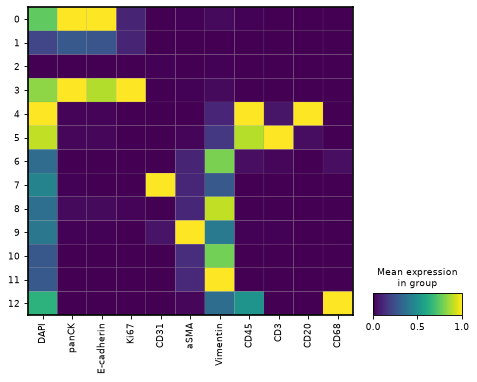

In [9]:
sc.pl.matrixplot(adata, CHANNELS, groupby="cluster", standard_scale="var", figsize=(7, 5))

## Comparison with the known structures

Since the image is synthetic, we know the structure of every pixel. The fraction of each structure in each cluster
shows that every structure has a cluster of its own, while the stroma, the largest structure, is split into several
clusters. They differ in the intensities of Vimentin and DAPI, which the texture varies across the image: the map has
many nodes for the stroma, as most pixels are stroma, and Leiden splits them along these gradients. Another cluster,
with intermediate panCK and E-cadherin, collects pixels at the edges of the glands, which the blur mixes with the
lumen. On real data, such clusters are merged or set apart when the clusters are annotated by their marker profiles.

ARI 0.493


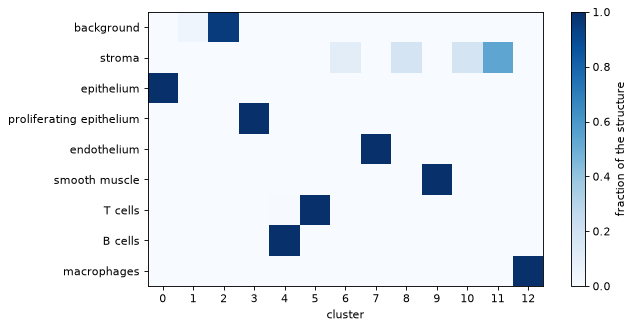

In [10]:
fractions = pd.crosstab(adata.obs["structure"], adata.obs["cluster"], normalize="index")

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
img = ax.imshow(fractions, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(fractions.shape[1]), fractions.columns)
ax.set_yticks(range(fractions.shape[0]), fractions.index)
ax.set_xlabel("cluster")
fig.colorbar(img, label="fraction of the structure")
print(f"ARI {adjusted_rand_score(adata.obs['structure'], adata.obs['cluster']):.3f}")

The resolution of the Leiden clustering sets how finely the nodes are split. At lower resolutions the stroma stays
together, but rarer structures merge with others:

In [11]:
def best_f1(truth, clusters):
    """F1 score of every structure with the cluster that matches it best."""
    table = pd.crosstab(truth, clusters)
    precision = table / table.sum(axis=0)
    recall = table.div(table.sum(axis=1), axis=0)
    return (2 * precision * recall / (precision + recall)).fillna(0).max(axis=1)


results = {}
for resolution in (0.2, 0.4, 0.7, 1.0):
    sc.tl.leiden(nodes, resolution=resolution, flavor="igraph", n_iterations=2, directed=False, random_state=0)
    clusters = nodes.obs["leiden"].to_numpy()[pixel_node]
    results[f"{resolution} ({nodes.obs['leiden'].nunique()} clusters)"] = best_f1(adata.obs["structure"], clusters)
pd.DataFrame(results).rename_axis(columns="resolution: F1 per structure").round(2)

resolution: F1 per structure,0.2 (6 clusters),0.4 (9 clusters),0.7 (12 clusters),1.0 (13 clusters)
structure,,,,
background,1.00,1.00,0.98,0.98
stroma,1.00,0.87,0.71,0.70
epithelium,0.82,1.00,1.00,1.00
proliferating epithelium,0.46,1.00,1.00,1.00
endothelium,0.45,0.99,0.99,1.00
smooth muscle,0.82,0.98,0.98,0.98
T cells,0.72,0.72,0.99,0.98
B cells,0.56,0.56,0.99,0.99
macrophages,1.00,1.00,0.82,1.00


## Next steps

- On a GPU, set `DEVICE = None`; maps of 30 x 30 nodes or more fit millions of pixels in seconds (see
  [](../guide/devices.md)).
- Under `metric="cosine"` pixels are compared by the direction of their marker profile, so that pixels of the same
  structure at different overall intensities share nodes (see [](../guide/distances.md)).
- With the clusters in an AnnData object with spatial coordinates in `obsm["spatial"]`, the
  [squidpy](https://squidpy.readthedocs.io) tools for spatial statistics, such as neighbourhood enrichment, apply.